Basic ML (1 real input and 1 real output) - Polinomial regression + Regularization

In [46]:
import numpy as np # numerical things
import numpy.matlib as nml # matricial computations
import matplotlib.pyplot as plt # plots

In [47]:
np.random.seed(13)

In [48]:
def oracle(x):
  return x**2

In [49]:
n = 5
sigma = 0.1
nt = 1000

In [50]:
x = np.random.rand(n)
y = oracle(x) + sigma * np.random.randn(n)
xt = np.linspace(0,1,nt)
yt = oracle(xt)

In [51]:
x = np.asmatrix(x).transpose()
y = np.asmatrix(y).transpose()
xt = np.asmatrix(xt).transpose()
yt = np.asmatrix(yt).transpose()

In [52]:
# Now I want to use polynomial regression + regularization -> new model (X' * X + lam * M) * c = X' * y
p = 10
lam = 100
M = nml.zeros((p+1, p+1))

for i in range(2, p+1):
  for j in range(2, p+1):
    M[i,j] = i * (i-1) * j * (j-1) / (i+j-3)

X = nml.ones((n,1))
Xt = nml.ones((nt,1))

for i in range (1, p+1):
  X = np.concatenate((X,np.power(x,i)), axis=1)
  Xt = np.concatenate((Xt,np.power(xt,i)), axis=1)
c = np.linalg.solve(X.T*X+lam*M, X.T*y)
yp = np.matmul(Xt,c)
err = np.mean(np.power(yt-yp,2))
print(str(p), "", str(err))

10  0.01875500461756453


Comments on the results:

1.  n = 5, sigma = 0.1, nt = 1000, p = 10, lam = 1

    - the model aproximation with p = 10 (model of grade 10) is visually similar to a straight line (polynome of grade 1). This is because my model has the form

        | X c - y | ^2 + lam c' M c

        which means that I have used a polynome of degree 10, but the coefficient of my model should cause this quantity (c' M c) to be small. That quantity represents the numer of oscillations.
    - If I have a large lambda, my model will be very simple, while if my lambda is small (ex: 0), the model will fit a lot the data (complex). If I put a small lambda, it means that I do not care about semplicity, but about making small error.

Smaller lambdas:

2. Same as before, but lam = 0.00001
    - the functions seems like a polynome of degree 10 : I am trying to fit the data
3. Same as before, but lam = 0.0000001
    - even more complex function

Larger lambdas:

4. lam = 100
    - the model tends to be as simple as possile
    - in this case the graph looks like a straight line because it does not have any oscillations -> also if I put lam = 1000, I will still get a straight line

Images of the models varying lambda:

lambda = 1  

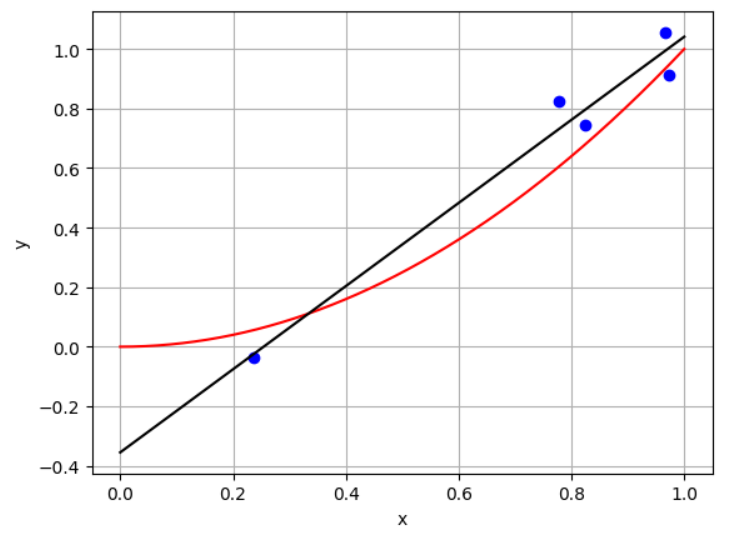

lambda = 1e-05  

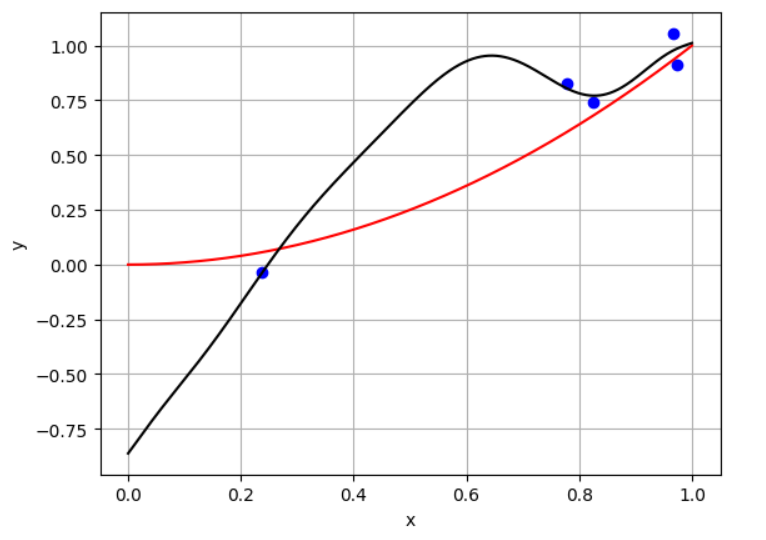

lambda = 1e-07  

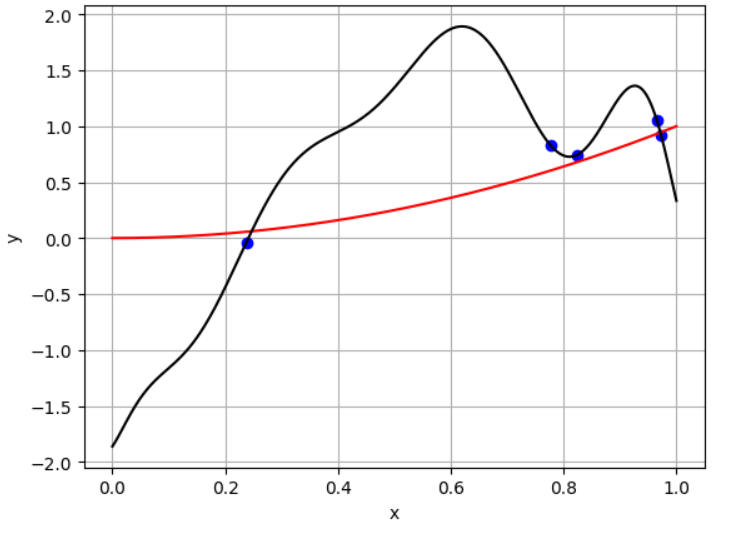

lambda = 100  

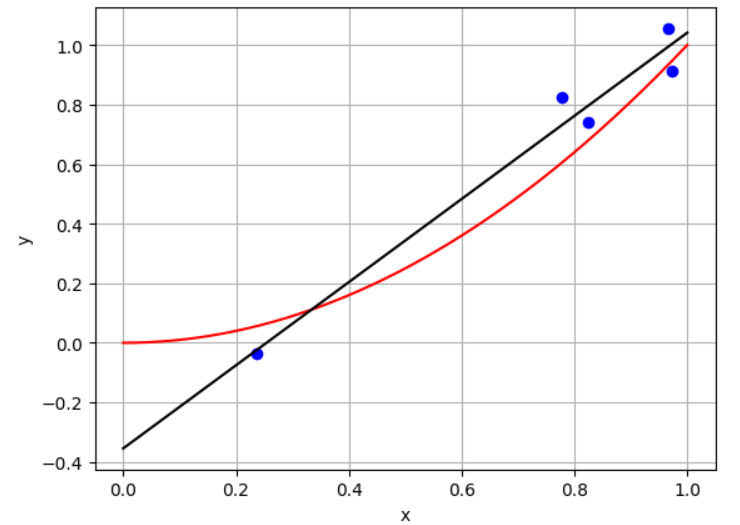

In [61]:
from IPython.display import Image, display

image_paths = [
    "/content/p10lam1.png",
    "/content/p10lam00001.png",
    "/content/p10lam0000001.png",
    "/content/p10lam100.png",
]

lambda_arr = [1, 0.00001, 0.0000001, 100]

for i, path in enumerate(image_paths):
    print(f"lambda = {lambda_arr[i]}", end="  ")
    display(Image(filename=path, width=200))
